In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [14]:
data = {
    "Student_ID": range(1, 31),

    "Gender": [
        "Female", "Male", "Female", "Male", "Female",
        "Male", "Female", "Male", "Female", "Male",
        "Female", "Male", "Female", "Male", "Female",
        "Male", "Female", "Male", "Female", "Male",
        "Female", "Male", "Female", "Male", "Female",
        "Male", "Female", "Male", "Female", "Male"
    ],

    "Study_Hours": [
        2, 3, 4, 5, 3, 6, 7, 4, 5, 8,
        6, 3, 9, 7, 4, 8, 5, 6, 10, 7,
        3, 9, 6, 5, 8, 4, 7, 10, 6, 5
    ],

    "Attendance": [
        65, 70, 75, 80, 72, 85, 90, 68, 78, 92,
        88, 73, 95, 89, 76, 91, 82, 86, 98, 90,
        71, 96, 84, 79, 93, 74, 88, 97, 85, 81
    ],

    "Exam_Score": [
        45, 50, 55, 65, 52, 70, 80, 48, 60, 85,
        75, 53, 92, 82, 58, 88, 67, 73, 96, 84,
        51, 94, 76, 62, 90, 56, 81, 98, 74, 66
    ]
}

df = pd.DataFrame(data)

# Introduce a few missing values for cleaning practice
df.loc[2, "Study_Hours"] = np.nan
df.loc[8, "Exam_Score"] = np.nan
df.loc[12, "Attendance"] = np.nan
df.loc[15, "Gender"] = np.nan

# Add one duplicate record for cleaning practice
df.loc[30] = df.loc[0].copy()

# Save original dataset
df.to_csv("student_academic_original.csv", index=False)

print("Dataset created successfully!")
print("Original dataset shape:", df.shape)

df.head()

Dataset created successfully!
Original dataset shape: (31, 5)


,Student_ID,Gender,Study_Hours,Attendance,Exam_Score
0,1,Female,2.0,65.0,45.0
1,2,Male,3.0,70.0,50.0
2,3,Female,NaN,75.0,55.0
3,4,Male,5.0,80.0,65.0
4,5,Female,3.0,72.0,52.0


In [15]:
print("Dataset Information:")
df.info()

print("\nFirst 10 Records:")
print(df.head(10))

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
Index: 31 entries, 0 to 30
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Student_ID   31 non-null     int64  
 1   Gender       30 non-null     object 
 2   Study_Hours  30 non-null     float64
 3   Attendance   30 non-null     float64
 4   Exam_Score   30 non-null     float64
dtypes: float64(3), int64(1), object(1)
memory usage: 1.5+ KB

First 10 Records:
   Student_ID  Gender  Study_Hours  Attendance  Exam_Score
0           1  Female          2.0        65.0        45.0
1           2    Male          3.0        70.0        50.0
2           3  Female          NaN        75.0        55.0
3           4    Male          5.0        80.0        65.0
4           5  Female          3.0        72.0        52.0
5           6    Male          6.0        85.0        70.0
6           7  Female          7.0        90.0        80.0
7           8    Male          4.0 

In [16]:
print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

Missing Values:
Student_ID     0
Gender         1
Study_Hours    1
Attendance     1
Exam_Score     1
dtype: int64

Total Missing Values:
4

Duplicate Records:
1


In [17]:
cleaned_df = df.copy()

# Fill missing numerical values with median
numerical_columns = [
    "Study_Hours",
    "Attendance",
    "Exam_Score"
]

for column in numerical_columns:
    cleaned_df[column] = cleaned_df[column].fillna(
        cleaned_df[column].median()
    )

# Fill missing categorical values with mode
cleaned_df["Gender"] = cleaned_df["Gender"].fillna(
    cleaned_df["Gender"].mode()[0]
)

# Remove duplicate records
cleaned_df = cleaned_df.drop_duplicates()

# Reset index
cleaned_df = cleaned_df.reset_index(drop=True)

print("Data cleaning completed!")
print("Original records:", len(df))
print("Cleaned records:", len(cleaned_df))

cleaned_df.head()

Data cleaning completed!
Original records: 31
Cleaned records: 30


,Student_ID,Gender,Study_Hours,Attendance,Exam_Score
0,1,Female,2.0,65.0,45.0
1,2,Male,3.0,70.0,50.0
2,3,Female,6.0,75.0,55.0
3,4,Male,5.0,80.0,65.0
4,5,Female,3.0,72.0,52.0


In [18]:
print("Missing Values After Cleaning:")
print(cleaned_df.isnull().sum())

print("\nDuplicate Records After Cleaning:")
print(cleaned_df.duplicated().sum())

print("\nCleaned Dataset Shape:")
print(cleaned_df.shape)

# Save cleaned dataset
cleaned_df.to_csv("student_academic_cleaned.csv", index=False)

print("\nCleaned dataset saved successfully!")

Missing Values After Cleaning:
Student_ID     0
Gender         0
Study_Hours    0
Attendance     0
Exam_Score     0
dtype: int64

Duplicate Records After Cleaning:
0

Cleaned Dataset Shape:
(30, 5)

Cleaned dataset saved successfully!


In [19]:
print("DESCRIPTIVE STATISTICS")
print("----------------------")

print(cleaned_df.describe())

print("\nAverage Study Hours:",
      round(cleaned_df["Study_Hours"].mean(), 2))

print("Average Attendance:",
      round(cleaned_df["Attendance"].mean(), 2))

print("Average Exam Score:",
      round(cleaned_df["Exam_Score"].mean(), 2))

print("\nGender Distribution:")
print(cleaned_df["Gender"].value_counts())

DESCRIPTIVE STATISTICS
----------------------
       Student_ID  Study_Hours  Attendance  Exam_Score
count   30.000000    30.000000   30.000000   30.000000
mean    15.500000     5.900000   82.633333   71.250000
std      8.803408     2.155186    9.030536   15.793249
min      1.000000     2.000000   65.000000   45.000000
25%      8.250000     4.250000   75.250000   56.500000
50%     15.500000     6.000000   83.500000   72.250000
75%     22.750000     7.000000   89.750000   83.500000
max     30.000000    10.000000   98.000000   98.000000

Average Study Hours: 5.9
Average Attendance: 82.63
Average Exam Score: 71.25

Gender Distribution:
Gender
Female    16
Male      14
Name: count, dtype: int64


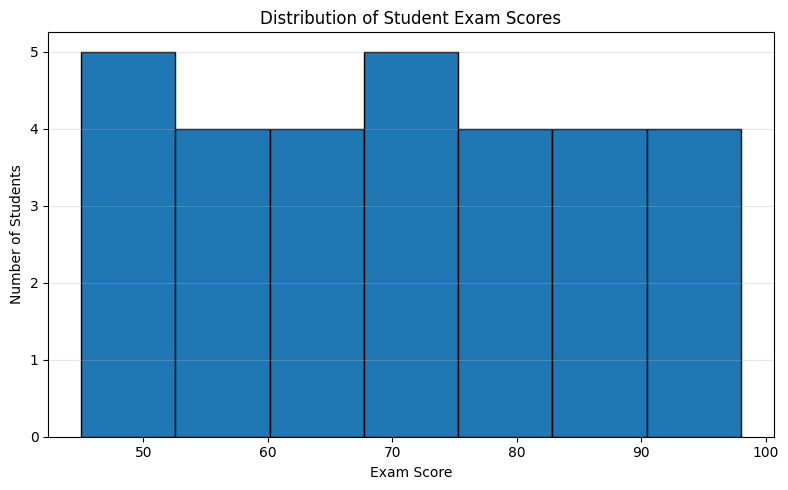

In [20]:
plt.figure(figsize=(8, 5))

plt.hist(
    cleaned_df["Exam_Score"],
    bins=7,
    edgecolor="black"
)

plt.title("Distribution of Student Exam Scores")
plt.xlabel("Exam Score")
plt.ylabel("Number of Students")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("01_exam_score_histogram.png", dpi=300)
plt.show()

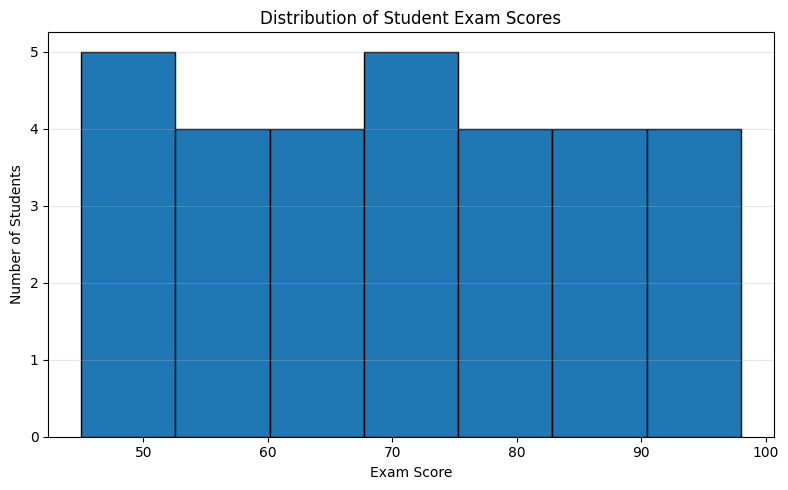

In [21]:
plt.figure(figsize=(8, 5))

plt.hist(
    cleaned_df["Exam_Score"],
    bins=7,
    edgecolor="black"
)

plt.title("Distribution of Student Exam Scores")
plt.xlabel("Exam Score")
plt.ylabel("Number of Students")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("01_exam_score_histogram.png", dpi=300)
plt.show()

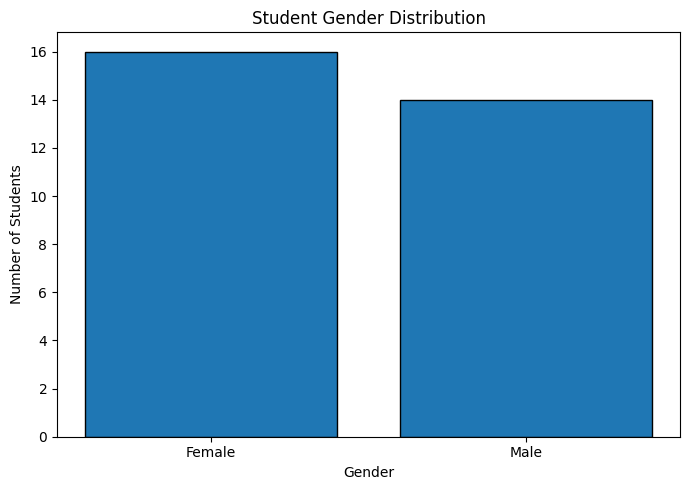

In [22]:
gender_counts = cleaned_df["Gender"].value_counts()

plt.figure(figsize=(7, 5))

plt.bar(
    gender_counts.index,
    gender_counts.values,
    edgecolor="black"
)

plt.title("Student Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.savefig("02_gender_distribution.png", dpi=300)
plt.show()

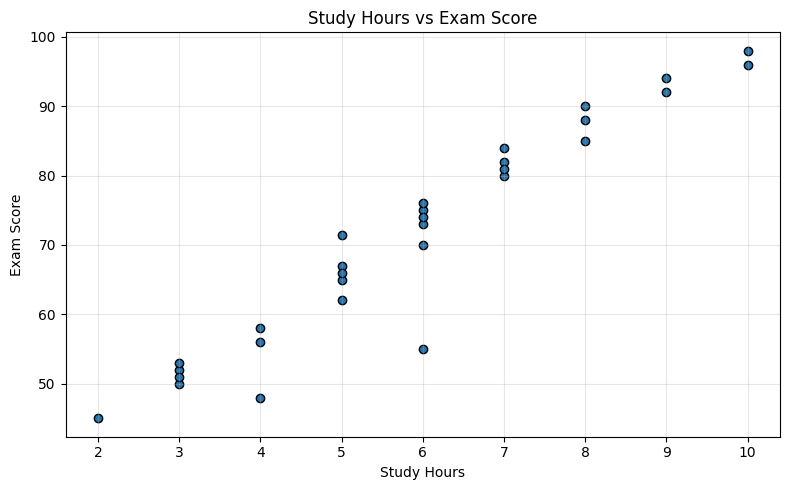

In [23]:
plt.figure(figsize=(8, 5))

plt.scatter(
    cleaned_df["Study_Hours"],
    cleaned_df["Exam_Score"],
    edgecolor="black"
)

plt.title("Study Hours vs Exam Score")
plt.xlabel("Study Hours")
plt.ylabel("Exam Score")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("03_study_hours_vs_score.png", dpi=300)
plt.show()

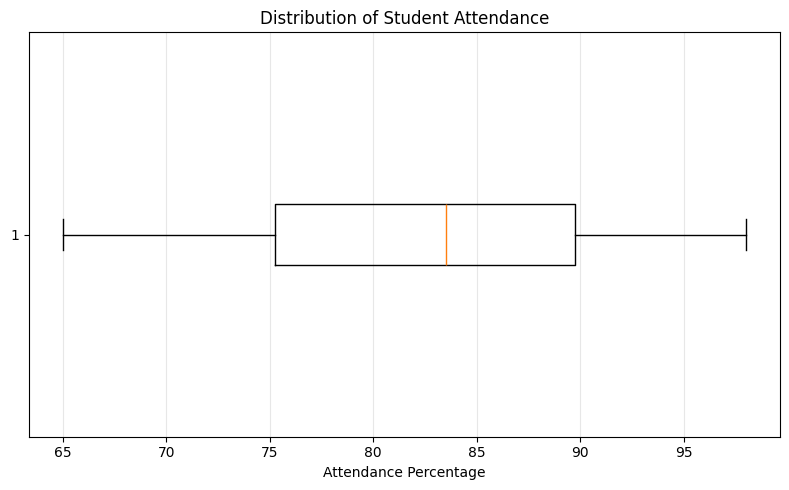

In [24]:
plt.figure(figsize=(8, 5))

plt.boxplot(
    cleaned_df["Attendance"],
    vert=False
)

plt.title("Distribution of Student Attendance")
plt.xlabel("Attendance Percentage")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.savefig("04_attendance_boxplot.png", dpi=300)
plt.show()

In [25]:
correlation = cleaned_df[
    ["Study_Hours", "Attendance", "Exam_Score"]
].corr()

print("CORRELATION MATRIX")
print(correlation)

print("\nStudy Hours vs Exam Score:",
      round(correlation.loc["Study_Hours", "Exam_Score"], 2))

print("Attendance vs Exam Score:",
      round(correlation.loc["Attendance", "Exam_Score"], 2))

CORRELATION MATRIX
             Study_Hours  Attendance  Exam_Score
Study_Hours     1.000000    0.921135    0.959644
Attendance      0.921135    1.000000    0.954117
Exam_Score      0.959644    0.954117    1.000000

Study Hours vs Exam Score: 0.96
Attendance vs Exam Score: 0.95


In [26]:
avg_study = cleaned_df["Study_Hours"].mean()
avg_attendance = cleaned_df["Attendance"].mean()
avg_score = cleaned_df["Exam_Score"].mean()

study_correlation = correlation.loc[
    "Study_Hours", "Exam_Score"
]

attendance_correlation = correlation.loc[
    "Attendance", "Exam_Score"
]

print("EDA OBSERVATIONS")
print("----------------")

print(
    f"1. The average study time is {avg_study:.2f} hours."
)

print(
    f"2. The average attendance is {avg_attendance:.2f}%."
)

print(
    f"3. The average exam score is {avg_score:.2f}."
)

print(
    f"4. Study hours and exam score have a correlation of "
    f"{study_correlation:.2f}."
)

print(
    f"5. Attendance and exam score have a correlation of "
    f"{attendance_correlation:.2f}."
)

print(
    "6. The histogram shows how student scores are distributed."
)

EDA OBSERVATIONS
----------------
1. The average study time is 5.90 hours.
2. The average attendance is 82.63%.
3. The average exam score is 71.25.
4. Study hours and exam score have a correlation of 0.96.
5. Attendance and exam score have a correlation of 0.95.
6. The histogram shows how student scores are distributed.


In [27]:
print("FINAL EDA SUMMARY")
print("-----------------")

print("Original dataset records:", len(df))
print("Cleaned dataset records:", len(cleaned_df))

print(
    "Missing values remaining:",
    cleaned_df.isnull().sum().sum()
)

print(
    "Duplicate records remaining:",
    cleaned_df.duplicated().sum()
)

print("\nVisualizations created: 4")

print("\nEDA completed successfully!")

FINAL EDA SUMMARY
-----------------
Original dataset records: 31
Cleaned dataset records: 30
Missing values remaining: 0
Duplicate records remaining: 0

Visualizations created: 4

EDA completed successfully!
